Outlier

Data out of given range , makes original data wrong , makes noice in data , give wrong prediction , out of bound values or data

In [83]:
#e.g data with no outlier
data = { 5, 5, 6, 4, 6, 4, 6, 5 , 8 , 5, 8, 9, 5, 4}
mean = sum(data)/len(data) 
mean

6.4

In [84]:
#e.g data with  outlier
data = { 5, 5, 6, 4, 6, 4, 6, 5 , 100 , 5, 8, 9, 5, 4}  # 100 is outlier
mean = sum(data)/len(data) 
mean

22.0

this gives wrong data calculations

How to deal with outlier 
1)Outlier Detection 
2)Outlier Removal

Outlier Detection

In [85]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [86]:
dataset = pd.read_excel(r"C:\Users\junai\Desktop\coding\ML\yahoo_data.xlsx")
dataset.head(10)

,Date,Open,High,Low,Close*,Adj Close**,Volume
0,"Apr 28, 2023",33797.43,34104.56,33728.40,34098.16,34098.16,354310000
1,"Apr 27, 2023",33797.43,33859.75,33374.65,33826.16,33826.16,343240000
2,"Apr 26, 2023",33596.34,33645.83,33235.85,33301.87,33301.87,321170000
3,"Apr 25, 2023",33828.34,33875.49,33525.39,33530.83,33.00,297880000
4,"Apr 24, 2023",33805.04,33891.15,33726.09,33875.40,33875.40,252020000
5,"Apr 21, 2023",33793.60,33858.83,33688.57,33808.96,33808.96,291080000
6,"Apr 20, 2023",33740.60,33875.39,33726.09,33786.62,33786.62,307910000
7,"Apr 19, 2023",33889.83,33957.98,33814.65,33897.01,33897.01,251490000
8,"Apr 18, 2023",33965.16,34018.62,33791.89,33976.63,33976.63,253570000
9,"Apr 17, 2023",33930.46,33991.23,33796.91,33987.18,33987.18,234530000


In [87]:
dataset.info

<bound method DataFrame.info of               Date      Open      High       Low    Close*  Adj Close**  \
0     Apr 28, 2023  33797.43  34104.56  33728.40  34098.16     34098.16   
1     Apr 27, 2023  33797.43  33859.75  33374.65  33826.16     33826.16   
2     Apr 26, 2023  33596.34  33645.83  33235.85  33301.87     33301.87   
3     Apr 25, 2023  33828.34  33875.49  33525.39  33530.83        33.00   
4     Apr 24, 2023  33805.04  33891.15  33726.09  33875.40     33875.40   
...            ...       ...       ...       ...       ...          ...   
1253  May 07, 2018  24317.66  24479.45  24263.42  24357.32     24357.32   
1254  May 04, 2018  23865.22  24333.35  23778.87  24262.51     24262.51   
1255  May 03, 2018  23836.23  23996.15  23531.31  23930.15     23930.15   
1256  May 02, 2018  24097.63  24185.52  23886.30  23924.98     23924.98   
1257  May 01, 2018  24117.29  24117.29  23808.19  24099.05     24099.05   

         Volume  
0     354310000  
1     343240000  
2     3211700

In [88]:
dataset.describe()

,Open,High,Low,Close*,Adj Close**,Volume
count,1258.000000,1258.000000,1258.000000,1258.000000,1.258000e+03,1.258000e+03
mean,29596.153545,29776.945739,29402.470660,29599.361677,2.067919e+06,3.450636e+08
std,4006.408015,4009.007573,4004.990359,4007.468822,6.632463e+07,1.069142e+08
min,19028.360000,19121.010000,18213.650000,18591.930000,2.300000e+01,8.615000e+07
25%,26041.267500,26163.155000,25877.872500,26027.120000,2.602530e+04,2.773125e+08
50%,29201.410000,29335.685000,28996.500000,29199.460000,2.919115e+04,3.247250e+08
75%,33618.672500,33825.445000,33346.827500,33600.342500,3.361139e+04,3.875100e+08
max,36722.600000,36952.650000,36636.000000,36799.650000,2.342111e+09,9.159900e+08


	2.300000e+01	and   2.342111e+09 are outliers in Adjclose

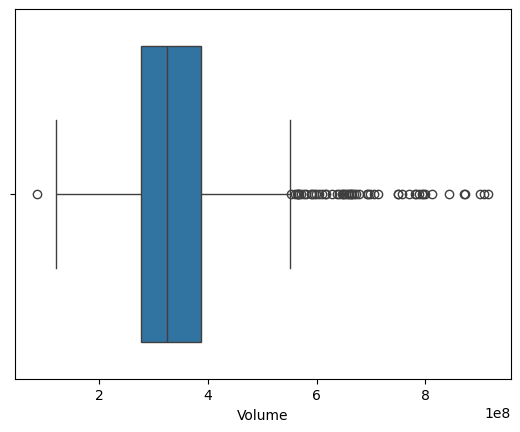

In [89]:
# we can use box plot or distribution plot to see outlier
# using box plot to see outlier
sns.boxplot(x = "Volume" , data = dataset )
plt.show()

Outliers in Volume

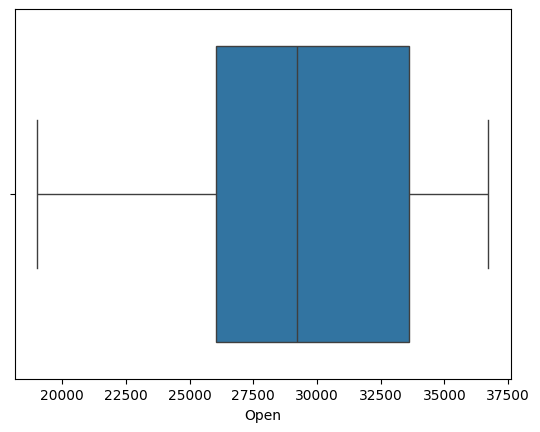

In [90]:
sns.boxplot(x = "Open" , data = dataset )
plt.show()

No outlier in Volume

C:\Users\junai\AppData\Local\Temp\ipykernel_13460\4215240840.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset["Adj Close**"])


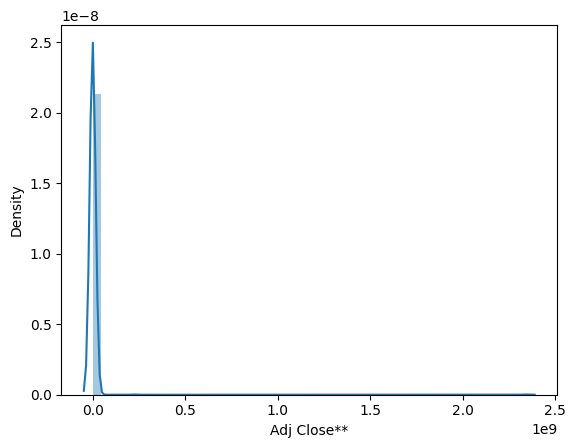

In [91]:
# using displot to check outlier
sns.distplot(dataset["Adj Close**"])
plt.show()  

Outlier in Adj Close**	 , check the tail , its very long

Removing Outlier

methods -> 1) IQR method
           2) Z Score method

IQR method  ( inter quintile range )

In [92]:
# e.g normal distribution

# min     Q1            Q3       max
# |--------|------------|--------|
# -100    -50     0     50      100
# 2.5            Q0             2.5
# 50%      25%          25%     50%  
#                 
# quintile range = Q3-Q1
# IQR = Q3 - Q1
# min = Q1 - (1.5 x IQR)
# max = Q3 + (1.5 x IQR)
# basically it consist of 50% of data which is most accurate

In [93]:
dataset.shape

(1258, 7)

In [94]:
#Rremoving outlier from Volume col
Q1 = dataset["Volume"].quantile(0.25)  # 25%
Q3 = dataset["Volume"].quantile(0.75)  # 75%
Q1 , Q3


(277312500.0, 387510000.0)

In [95]:
IQR = Q3-Q1

In [96]:
min_range = Q1 - ( 1.5 * IQR)
max_range = Q3 + ( 1.5 * IQR)
min_range , max_range  # if any negetive means outlier dosent exist in that range

(112016250.0, 552806250.0)

In [97]:
# since both positive , outlier exist in both
new_dataset = dataset[dataset["Volume"] <= max_range]   # remove beyond max range
new_dataset = new_dataset[new_dataset["Volume"] >=  min_range]    # remove beyond min range

In [98]:
dataset.shape

(1258, 7)

In [99]:
new_dataset.shape

(1203, 7)

u can see 1258 - 1203  = 55 outliers  removed

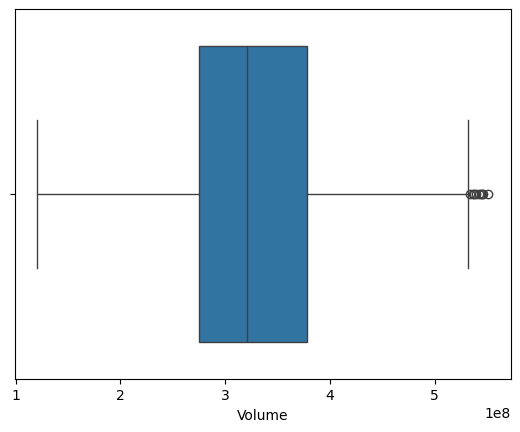

In [100]:
sns.boxplot(x = "Volume" , data = new_dataset )
plt.show()

therefore outlier minimized

Z score method

In [101]:
# .......................99%.......................
# .       ...............95%...............       .
# .       .       .......68%.......       .       .
# .       .       .               .       .       .
# |-------|-------|-------|-------|-------|-------|
# |       |       |       mU      |       |       |
# |       |      mU-d           mU+d      |       |
# |     mU-2d                           mU+2d     |
# mU-3d                                         mU+3d  

#everting beyound mU-3d and mU+3d is outlier
# z = ( x - mU) - d
# mU = mue ( mean )
# d = sigma ( standard deviaton)
# min = mU - 3d
# max = mU + 3d

In [102]:
#remove null values if any
# removing outlier of Adj Close**
# 1) directly 


In [103]:
min_range = dataset["Adj Close**"].mean() - ( 3*dataset["Adj Close**"].std())
max_range = dataset["Adj Close**"].mean() + ( 3*dataset["Adj Close**"].std())
min_range , max_range  # if any negetive means outlier dosent exist in that range

(-196905959.6519288, 201041797.20736602)

outlier exist in only max_range

In [104]:
new_dataset2 =dataset[dataset["Adj Close**"] <=  max_range] # remove beyond max range

In [105]:
dataset.shape , new_dataset2.shape

((1258, 7), (1256, 7))

1258 - 1256 = 2 outliers removed

C:\Users\junai\AppData\Local\Temp\ipykernel_13460\483327383.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_dataset2["Adj Close**"])


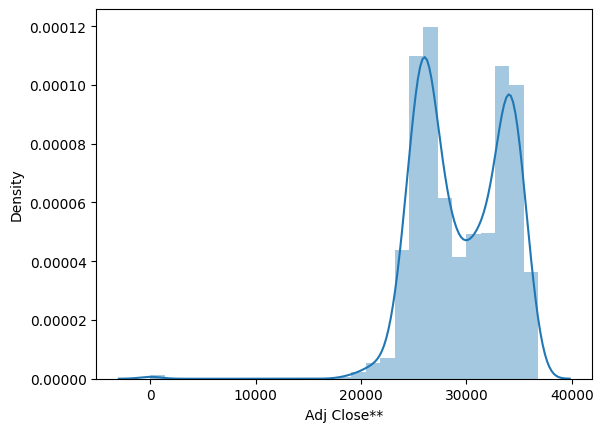

In [106]:
# using displot to check outlier
sns.distplot(new_dataset2["Adj Close**"])
plt.show()  

2) Using z-score formula

In [111]:
z_score =( dataset["Adj Close**"] - dataset["Adj Close**"].mean())/(dataset["Adj Close**"].std())
z_score

0      -0.030665
1      -0.030669
2      -0.030677
3      -0.031178
4      -0.030668
          ...   
1253   -0.030812
1254   -0.030813
1255   -0.030818
1256   -0.030818
1257   -0.030815
Name: Adj Close**, Length: 1258, dtype: float64

In [113]:
dataset["z_score"] = z_score
dataset

,Date,Open,High,Low,Close*,Adj Close**,Volume,z_score
0,"Apr 28, 2023",33797.43,34104.56,33728.40,34098.16,34098.16,354310000,-0.030665
1,"Apr 27, 2023",33797.43,33859.75,33374.65,33826.16,33826.16,343240000,-0.030669
2,"Apr 26, 2023",33596.34,33645.83,33235.85,33301.87,33301.87,321170000,-0.030677
3,"Apr 25, 2023",33828.34,33875.49,33525.39,33530.83,33.00,297880000,-0.031178
4,"Apr 24, 2023",33805.04,33891.15,33726.09,33875.40,33875.40,252020000,-0.030668
...,...,...,...,...,...,...,...,...
1253,"May 07, 2018",24317.66,24479.45,24263.42,24357.32,24357.32,307670000,-0.030812
1254,"May 04, 2018",23865.22,24333.35,23778.87,24262.51,24262.51,329480000,-0.030813
1255,"May 03, 2018",23836.23,23996.15,23531.31,23930.15,23930.15,389240000,-0.030818
1256,"May 02, 2018",24097.63,24185.52,23886.30,23924.98,23924.98,385350000,-0.030818


In [114]:
dataset[dataset["z_score"] < 3]

,Date,Open,High,Low,Close*,Adj Close**,Volume,z_score
0,"Apr 28, 2023",33797.43,34104.56,33728.40,34098.16,34098.16,354310000,-0.030665
1,"Apr 27, 2023",33797.43,33859.75,33374.65,33826.16,33826.16,343240000,-0.030669
2,"Apr 26, 2023",33596.34,33645.83,33235.85,33301.87,33301.87,321170000,-0.030677
3,"Apr 25, 2023",33828.34,33875.49,33525.39,33530.83,33.00,297880000,-0.031178
4,"Apr 24, 2023",33805.04,33891.15,33726.09,33875.40,33875.40,252020000,-0.030668
...,...,...,...,...,...,...,...,...
1253,"May 07, 2018",24317.66,24479.45,24263.42,24357.32,24357.32,307670000,-0.030812
1254,"May 04, 2018",23865.22,24333.35,23778.87,24262.51,24262.51,329480000,-0.030813
1255,"May 03, 2018",23836.23,23996.15,23531.31,23930.15,23930.15,389240000,-0.030818
1256,"May 02, 2018",24097.63,24185.52,23886.30,23924.98,23924.98,385350000,-0.030818


In [115]:
dataset

,Date,Open,High,Low,Close*,Adj Close**,Volume,z_score
0,"Apr 28, 2023",33797.43,34104.56,33728.40,34098.16,34098.16,354310000,-0.030665
1,"Apr 27, 2023",33797.43,33859.75,33374.65,33826.16,33826.16,343240000,-0.030669
2,"Apr 26, 2023",33596.34,33645.83,33235.85,33301.87,33301.87,321170000,-0.030677
3,"Apr 25, 2023",33828.34,33875.49,33525.39,33530.83,33.00,297880000,-0.031178
4,"Apr 24, 2023",33805.04,33891.15,33726.09,33875.40,33875.40,252020000,-0.030668
...,...,...,...,...,...,...,...,...
1253,"May 07, 2018",24317.66,24479.45,24263.42,24357.32,24357.32,307670000,-0.030812
1254,"May 04, 2018",23865.22,24333.35,23778.87,24262.51,24262.51,329480000,-0.030813
1255,"May 03, 2018",23836.23,23996.15,23531.31,23930.15,23930.15,389240000,-0.030818
1256,"May 02, 2018",24097.63,24185.52,23886.30,23924.98,23924.98,385350000,-0.030818


1258 - 1256 = 2 outliers deleted